# Customer Segmentation Using RFM, K-Means, and DBSCAN

## 1. Setup and Data Loading

### 1.1 Import Libraries

In [1]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

### 1.2 Load the Online Retail Dataset

In [2]:
df=pd.read_excel("Online Retail.xlsx")

## 2. Initial Data Inspection

### 2.1 Preview the Data

In [3]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


### 2.2 Dataset Structure and Summary Statistics

In [6]:
df.shape

(541909, 8)

In [7]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


### 2.3 Duplicate Rows

In [11]:
df.duplicated().sum()

np.int64(5268)

In [12]:
df=df.drop_duplicates()

### 2.4 Missing Values

In [13]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

### 2.5 Invalid Quantities and Unit Prices

In [14]:
# not valid quantity
(df['Quantity']<0).sum()

np.int64(10587)

In [15]:
# not valid prices
(df['UnitPrice']<=0).sum()

np.int64(2512)

### 2.6 Cancelled Invoices

In [16]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()


np.int64(9251)

### 2.7 Number of Unique Customers

In [17]:
df["CustomerID"].nunique()

4372

## 3. Data Cleaning

### 3.1 Remove Missing CustomerID

In [18]:
df = df.dropna(
    subset=["CustomerID", "InvoiceDate"])

### 3.2 Convert CustomerID to String

In [19]:
df["CustomerID"]=df["CustomerID"].astype("int64").astype("str")

### 3.3 Remove Cancelled Invoices

In [20]:
# Remove cancelled invoices
df.drop(df[df["InvoiceNo"].astype(str).str.startswith("C")].index,inplace=True)

### 3.4 Remove Non-Positive Quantity and UnitPrice

In [21]:
# Remove invalid quantities and prices
df=df[(df["UnitPrice"]>0) & (df["Quantity"]>0)]

### 3.5 Create the TotalPrice Feature

In [22]:
df["TotalPrice"]=df["UnitPrice"]*df["Quantity"]

### 3.6 Post-Cleaning Validation

Check

In [23]:
df.shape

(392692, 9)

In [24]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

In [25]:
df["CustomerID"].nunique()

4338

## 4. Customer-Level RFM Table

### 4.1 Reference Date

In [26]:
reference_date = df["InvoiceDate"].max()
reference_date

Timestamp('2011-12-09 12:50:00')

### 4.2 Build the RFM Table

In [27]:
#create RFM table
rfm=df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",lambda x :(reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

### 4.3 RFM Table Checks and Summary Statistics

In [28]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,325,1,77183.60
1,12347,1,7,4310.00
2,12348,74,4,1797.24
3,12349,18,1,1757.55
4,12350,309,1,334.40


In [29]:
rfm.shape

(4338, 4)

In [30]:
rfm.isnull().sum()

CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

In [31]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,91.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,306.482500
50%,50.000000,2.000000,668.570000
75%,141.000000,5.000000,1660.597500
max,373.000000,209.000000,280206.020000


### 4.4 Cleaning Summary (Retained Invoices and Customers)

In [32]:
print("Retained invoices:", df["InvoiceNo"].nunique())
print("Retained customers:", rfm["CustomerID"].nunique())

Retained invoices: 18532
Retained customers: 4338


## 5. RFM Distribution, Transformation, and Scaling

### 5.1 RFM Distributions (Histograms)

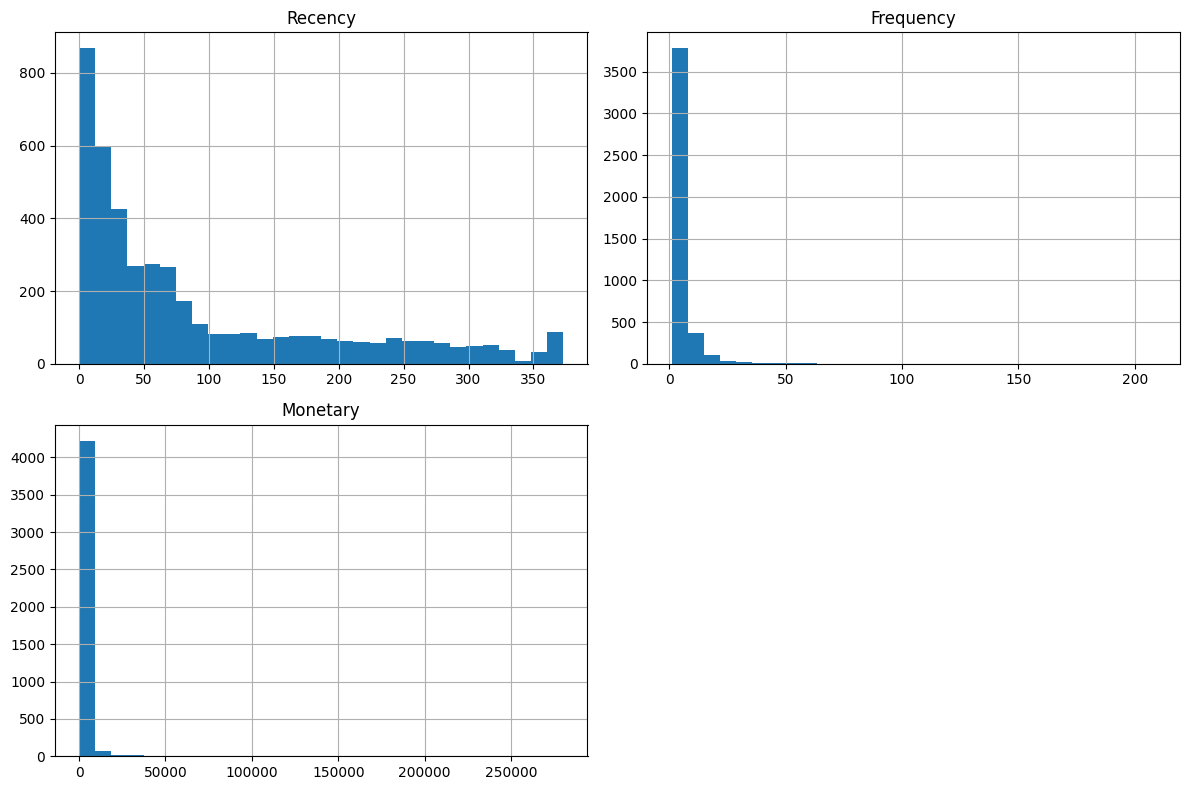

In [33]:
rfm[["Recency", "Frequency", "Monetary"]].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

### 5.2 Skewness Before Transformation

In [34]:
print(rfm[["Recency", "Frequency", "Monetary"]].skew())

Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64


### 5.3 Log Transformation (log1p)

In [35]:
import numpy as np

rfm["Frequency_log"] = np.log1p(rfm["Frequency"])
rfm["Monetary_log"] = np.log1p(rfm["Monetary"])

### 5.4 Skewness After Transformation

In [36]:
print(rfm[["Frequency_log", "Monetary_log"]].skew())

Frequency_log    1.208652
Monetary_log     0.396599
dtype: float64


### 5.5 Feature Standardization (StandardScaler)

In [37]:
features = ["Recency", "Frequency_log", "Monetary_log"]
scalar = StandardScaler()
X_Scaled=scalar.fit_transform(rfm[features])

In [38]:
print(X_Scaled.shape)

(4338, 3)


## 6. K-Means Model Selection

### 6.1 Elbow Method

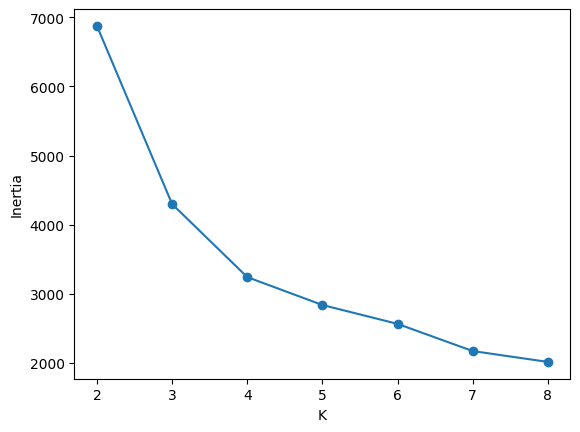

In [39]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_Scaled)
    inertias.append(model.inertia_)

plt.plot(range(2, 9), inertias,marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

### 6.2 Inertia and Silhouette Scores for k = 2 to 8

In [40]:
results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_Scaled)

    results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette": silhouette_score(X_Scaled, labels)
    })

results_df = pd.DataFrame(results)

print(results_df)

   k      inertia  silhouette
0  2  6874.932051    0.406237
1  3  4299.066899    0.415697
2  4  3243.032792    0.379542
3  5  2760.794356    0.343481
4  6  2396.854906    0.329923
5  7  2166.958608    0.300766
6  8  1961.088789    0.299870


### 6.3 Validation Plots (Elbow and Silhouette)

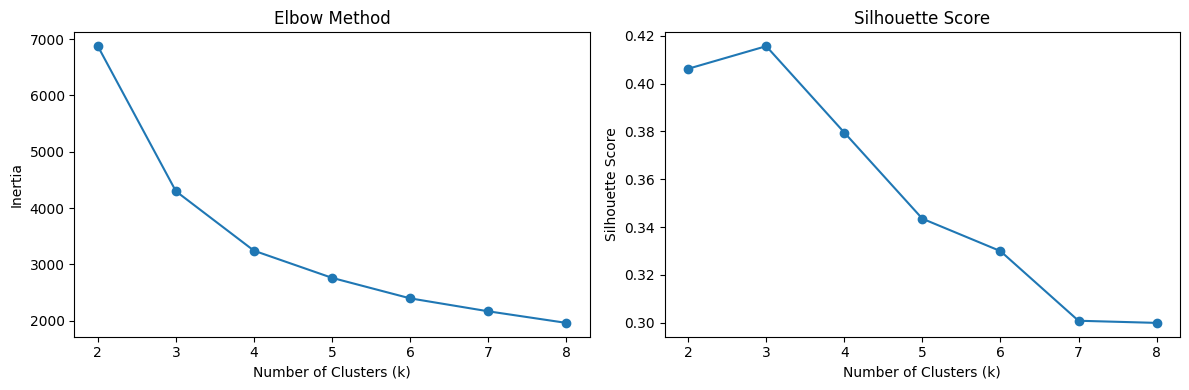

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(results_df["k"], results_df["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(results_df["k"], results_df["silhouette"], marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

## 7. Final K-Means Model (k = 3) and Segment Profiling

### 7.1 Fit K-Means with k = 3

In [42]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_Scaled)

print(rfm.head())

  CustomerID  Recency  Frequency  Monetary  Frequency_log  Monetary_log  \
0      12346      325          1  77183.60       0.693147     11.253955   
1      12347        1          7   4310.00       2.079442      8.368925   
2      12348       74          4   1797.24       1.609438      7.494564   
3      12349       18          1   1757.55       0.693147      7.472245   
4      12350      309          1    334.40       0.693147      5.815324   

   Cluster  
0        0  
1        0  
2        0  
3        2  
4        1  


In [43]:
rfm["Segment"] = rfm["Cluster"].map({
    0: "Frequent Customers",
    1: "Inactive Customers",
    2: "Regular Customers"
})

rfm[["CustomerID", "Segment"]].to_csv("customer_segments.csv", index=False)

print("File saved successfully")

File saved successfully


### 7.2 Cluster Sizes

In [44]:
rfm["Cluster"].value_counts().sort_index()

Cluster
0    1320
1     981
2    2037
Name: count, dtype: int64

### 7.3 Segment Profile (Size and Median RFM)

In [45]:
cluster_profile = rfm.groupby("Cluster").agg(
    Size=("CustomerID", "count"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median")
)

print(cluster_profile)

         Size  Recency_median  Frequency_median  Monetary_median
Cluster                                                         
0        1320            16.0               7.0         2570.495
1         981           252.0               1.0          290.510
2        2037            44.0               2.0          508.800


## 8. DBSCAN Clustering

### 8.1 Parameter Sensitivity (eps and min_samples)

In [46]:
settings = [(0.5, 5),(1.0, 5),(1.5, 10)]

for eps, min_samples in settings:
    model =DBSCAN(min_samples=min_samples,eps=eps)

    labels = model.fit_predict(X_Scaled)

    n_clusters = len(set(labels) - {-1})
    noise_ratio = np.mean(labels == -1)

    print(f"\neps={eps}, min_samples={min_samples}")
    print("Number of clusters:", n_clusters)
    print("Noise proportion:", round(noise_ratio, 3))

    mask = labels != -1
    remaining_labels = labels[mask]
    n_remaining_clusters = len(set(remaining_labels))

    if 2 <= n_remaining_clusters < len(remaining_labels):
        score = silhouette_score(
            X_Scaled[mask],
            remaining_labels
        )
        print("Silhouette:", round(score, 4))
    else:
        print("Silhouette: not applicable")


eps=0.5, min_samples=5
Number of clusters: 2
Noise proportion: 0.011
Silhouette: 0.3268

eps=1.0, min_samples=5
Number of clusters: 1
Noise proportion: 0.002
Silhouette: not applicable

eps=1.5, min_samples=10
Number of clusters: 1
Noise proportion: 0.001
Silhouette: not applicable


## 9. PCA Visualization of K-Means Segments

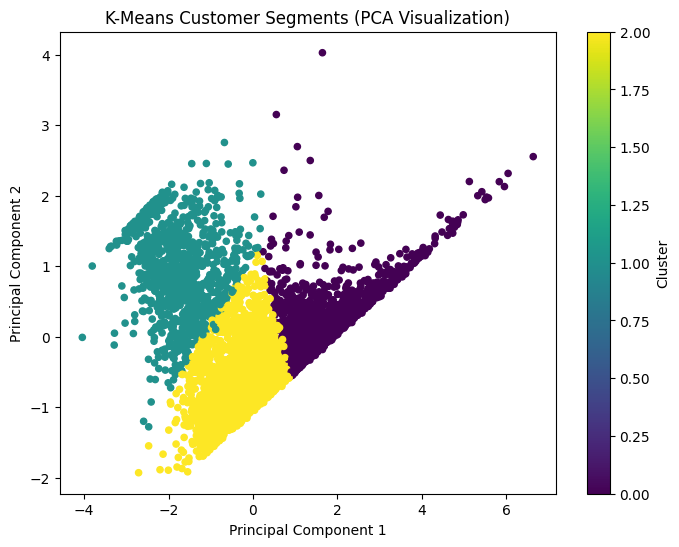

In [47]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_Scaled)

plt.figure(figsize=(8,6))
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=rfm["Cluster"],
    cmap="viridis",
    s=20
)

plt.title("K-Means Customer Segments (PCA Visualization)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()